In [1]:
import numpy as np
from manifold3d import Manifold, Mesh
import k3d
import trimesh
from pathlib import Path

In [3]:
def create_box_manifold(width, length, height, z_offset=0.0):
    """Generates a Manifold object for a solid rectangular box."""
    # 1. Define 8 vertices for a straight box
    vertices = np.array([
        # Bottom 4 vertices (z = z_offset)
        [-width / 2, -length / 2, z_offset],  # 0: Bottom-left
        [ width / 2, -length / 2, z_offset],  # 1: Bottom-right
        [ width / 2,  length / 2, z_offset],  # 2: Top-right
        [-width / 2,  length / 2, z_offset],  # 3: Top-left
        
        # Top 4 vertices (z = height + z_offset)
        [-width / 2, -length / 2, height + z_offset],  # 4: Top-left (Upper)
        [ width / 2, -length / 2, height + z_offset],  # 5: Top-right (Upper)
        [ width / 2,  length / 2, height + z_offset],  # 6: Bottom-right (Upper)
        [-width / 2,  length / 2, height + z_offset],  # 7: Bottom-left (Upper)
    ], dtype=np.float32)

    # 2. Define 12 triangular faces
    faces = np.array([
        [0, 2, 1], [0, 3, 2],  # Bottom
        [4, 5, 6], [4, 6, 7],  # Top
        [0, 1, 5], [0, 5, 4],  # Front
        [1, 2, 6], [1, 6, 5],  # Right
        [2, 3, 7], [2, 7, 6],  # Back
        [3, 0, 4], [3, 4, 7],  # Left
    ], dtype=np.int32)

    # 3. Construct the native Manifold object
    mesh = Mesh(vert_properties=vertices, tri_verts=faces)
    return Manifold(mesh)


def create_hollow_box(in_w, in_l, h, thickness):
    """
    Creates a hollow rectangular box (tube) defined by its INNER dimensions.
    Top and bottom are fully open.
    
    in_w, in_l: inner width and length
    h: total height of the box
    thickness: wall thickness
    """
    # 1. Calculate outer dimensions directly (just add thickness to both sides)
    out_w = in_w + (2 * thickness)
    out_l = in_l + (2 * thickness)
    out_h = h

    # 2. Calculate inner cutting dimensions
    # Extend the inner box by 1 unit on top and bottom to ensure a clean Boolean cut
    z_extend = 1.0
    ext_in_h = h + (2 * z_extend)

    # 3. Build Outer and Inner Manifolds
    outer = create_box_manifold(out_w, out_l, out_h, z_offset=0.0)
    
    # Push the inner box down by z_extend so it cuts completely through the floor and ceiling
    inner = create_box_manifold(in_w, in_l, ext_in_h, z_offset=-z_extend)

    # 4. Native Boolean Difference
    hollow_box = outer - inner
    
    return hollow_box

base_box = create_hollow_box(in_w=50, in_l=50, h=25, thickness=2.0)
# 1. Convert the Manifold object to a raw mesh
mesh_data = base_box.to_mesh()

# 2. Extract vertices and faces, enforcing K3D's required data types
vertices = mesh_data.vert_properties[:, :3].astype(np.float32)
indices = mesh_data.tri_verts.astype(np.uint32)

# 3. Initialize the K3D plot
plot = k3d.plot(name="Hollow Pyramid")

# 4. Create the K3D mesh object (you can customize colors and shading here)
mesh_vis = k3d.mesh(
    vertices,
    indices,
    color=0x00A0FF,  # Hex color (e.g., light blue)
    wireframe=False,  # Set to True to see the topology
    side="double",  # Renders both inside and outside faces
)

# 5. Add the mesh to the plot and display it
plot += mesh_vis
plot.display()

Output()

In [4]:
hollow_frustum, out_b_w, out_b_l = create_hollow_frustum(in_b_w=50.0, in_b_l=50.0, in_t_w=5.56, in_t_l=5.56, in_h=25.0, thickness=2.0)

box_in_w = 52.0  # Example inner width for the box
base_box = create_hollow_box(in_w=box_in_w, in_l=box_in_w, h=25, thickness= out_b_w - box_in_w)
# shift the top frustum up by 25 units in the Z direction to sit on top of the base box
hollow_frustum = hollow_frustum.translate([0, 0, 25.0])

# 执行 Boolean Union 合并为一个完整的对象
full_collimator = base_box + hollow_frustum
mesh_data = full_collimator.to_mesh()

# 2. Extract vertices and faces, enforcing K3D's required data types
vertices = mesh_data.vert_properties[:, :3].astype(np.float32)
indices = mesh_data.tri_verts.astype(np.uint32)

# 3. Initialize the K3D plot
plot = k3d.plot(name="Hollow Pyramid")

# 4. Create the K3D mesh object (you can customize colors and shading here)
mesh_vis = k3d.mesh(
    vertices,
    indices,
    color=0x00A0FF,  # Hex color (e.g., light blue)
    wireframe=False,  # Set to True to see the topology
    side="double",  # Renders both inside and outside faces
)

# 5. Add the mesh to the plot and display it
plot += mesh_vis
plot.display()


Output()

In [24]:
hollow_frustum, out_b_w, out_b_l = create_hollow_frustum(in_b_w=50.0, in_b_l=50.0, in_t_w=5.56, in_t_l=5.56, in_h=25.0, thickness=2.0)

box_in_w = 52.0  # Example inner width for the box
base_box = create_hollow_box(in_w=box_in_w, in_l=box_in_w, h=25, thickness= 2.0)
# shift the top frustum up by 25 units in the Z direction to sit on top of the base box
hollow_frustum = hollow_frustum.translate([0, 0, 25.0])

# Boolean Union to combine the base box and the hollow frustum into a single object
full_collimator = base_box + hollow_frustum

full_collimator = full_collimator.rotate([0, -90, 0])  # Rotate 90 degrees around the X-axis to align with the STL



collimator_mesh = full_collimator.to_mesh()
verts = collimator_mesh.vert_properties[:, :3]
center = (verts.max(axis=0) + verts.min(axis=0)) / 2.0 
full_collimator = full_collimator.translate([-center[0], -center[1], -center[2]])

collimator_mesh = full_collimator.to_mesh()
# 2. Extract vertices and faces, enforcing K3D's required data types
collimator_verts = collimator_mesh.vert_properties[:, :3].astype(np.float32)
collimator_indices = collimator_mesh.tri_verts.astype(np.uint32)

stl_dir= Path('/Users/fanghan/Work/RPIL/research_notes/brain-spect-geometry/python/stl/')
stl_filename = 'BrainSPECT_Module.008.25mm_at_0.556.STL'
stl_mesh = trimesh.load(stl_dir / stl_filename, force='mesh') 
stl_mesh.apply_translation(-stl_mesh.centroid)

# Extract data from the loaded STL
stl_verts = stl_mesh.vertices.astype(np.float32)
stl_faces = stl_mesh.faces.astype(np.uint32)

# 3. Initialize the K3D Plot
plot = k3d.plot(name="Collimator Overlay")

# 4. Create the collimator visualization (Semi-transparent Blue)
collimator_k3d = k3d.mesh(
    collimator_verts, 
    collimator_indices, 
    color=0x00A0FF,       
    opacity=0.4,          
    side='double',        
    flat_shading=True,    # <-- ADD THIS: Forces crisp flat faces instead of smooth interpolation
    name="Full Collimator"
)

# 4b. Create the Sharp Edge Overlay (Black Wireframe)
collimator_edges = k3d.mesh(
    collimator_verts, 
    collimator_indices, 
    color=0x000000,       # Black lines
    wireframe=True,       # <-- ADD THIS: Renders the edges instead of solid faces
    name="Collimator Edges"
)

# 5. Create the STL visualization (Solid Orange)
stl_k3d = k3d.mesh(
    stl_verts, 
    stl_faces, 
    color=0xFF5733, 
    opacity=0.7,      
    side='double',
    flat_shading=True,    # <-- Optional, but usually looks better for imported STLs too
    name="Imported STL"
)

# 6. Add all three meshes to the plot
plot += collimator_k3d
plot += collimator_edges  # Add the edge overlay
plot += stl_k3d

plot.display()
output_file = 'centered_overlay.html'
with open(output_file, 'w') as f:
    f.write(plot.get_snapshot())

Output()

Saved: 'collimator_x_projection.png'


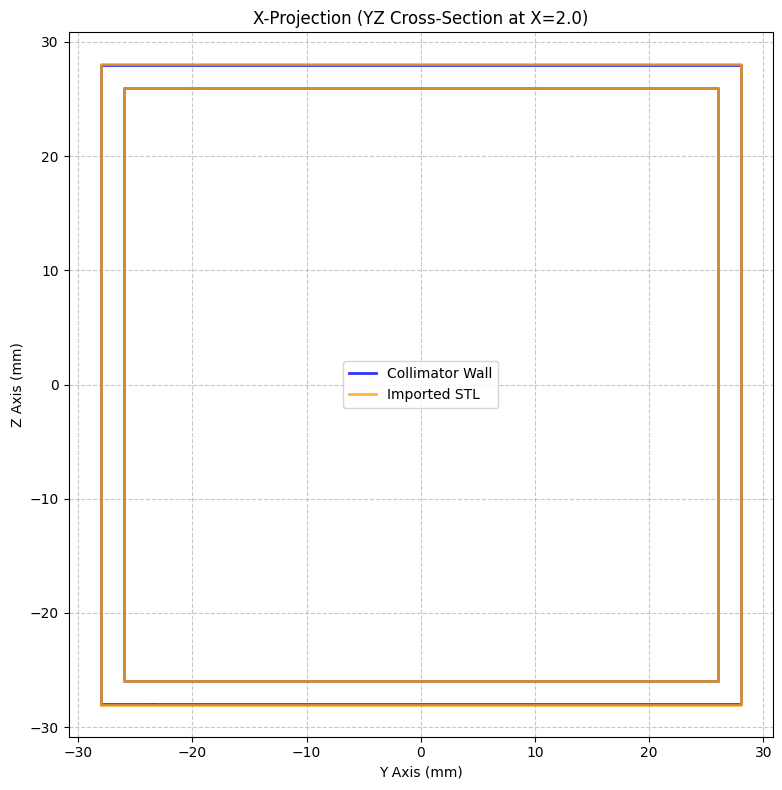

Saved: 'collimator_y_projection.png'


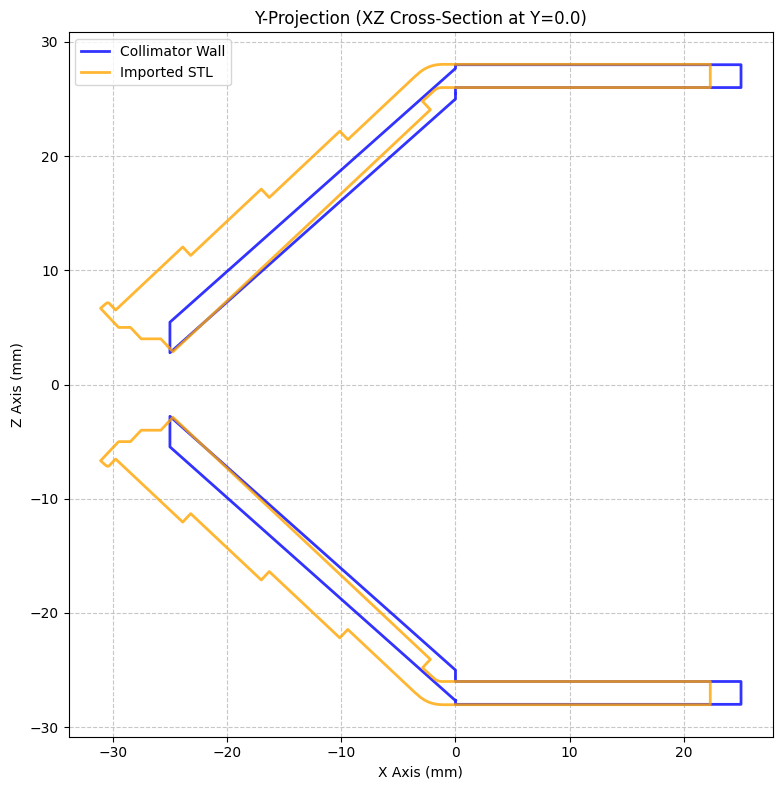

Saved: 'collimator_z_projection.png'


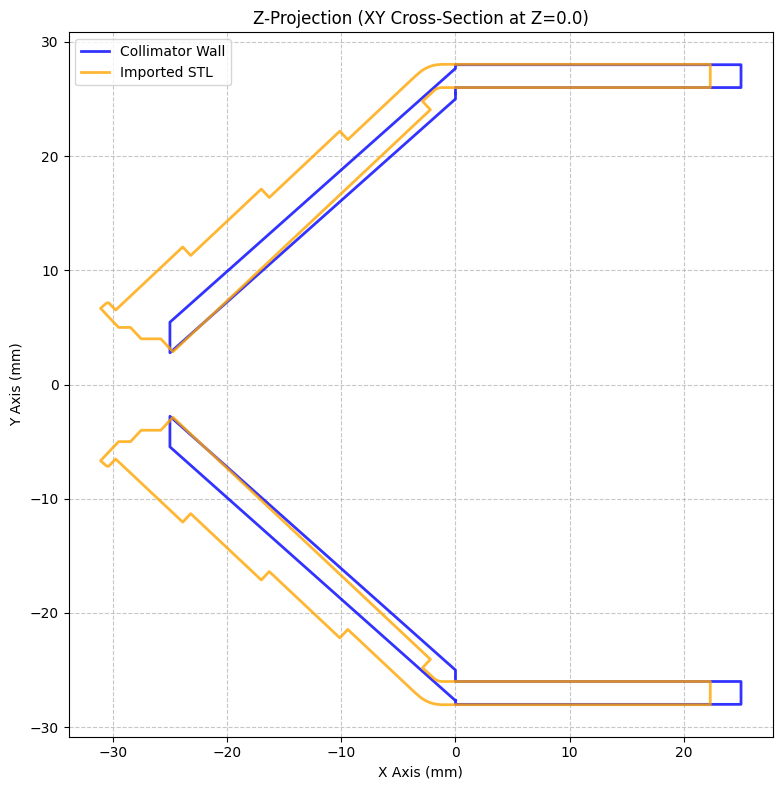

In [25]:
import matplotlib.pyplot as plt

# Ensure you have the Trimesh object created from your clean vertices
collimator_trimesh = trimesh.Trimesh(vertices=collimator_verts, faces=collimator_indices)

def plot_2d_projection(collimator, stl, origin, normal, x_idx, y_idx, x_label, y_label, title, filename):
    """
    Unified function to slice meshes and plot a 2D projection in a new window.
    """
    fig, ax = plt.subplots(figsize=(8, 8))
    
    # 1. Calculate the mathematical slice (cross-section)
    c_slice = collimator.section(plane_origin=origin, plane_normal=normal)
    s_slice = stl.section(plane_origin=origin, plane_normal=normal)
    
    # 2. Internal helper to draw the line segments
    def draw_slice(mesh_slice, color, label, alpha=1.0):
        if mesh_slice is not None:
            for i, segment in enumerate(mesh_slice.discrete):
                # We use x_idx and y_idx to pick the correct 3D coordinates for the 2D plot
                ax.plot(segment[:, x_idx], segment[:, y_idx], color=color, 
                        linewidth=2, label=label if i == 0 else "", alpha=alpha)

    # 3. Draw both slices
    draw_slice(c_slice, 'blue', 'Collimator Wall', alpha=0.8)
    draw_slice(s_slice, 'orange', 'Imported STL', alpha=0.8)
    
    # 4. Formatting
    ax.set_aspect('equal')
    ax.set_xlabel(x_label)
    ax.set_ylabel(y_label)
    ax.set_title(title)
    ax.grid(True, linestyle='--', alpha=0.7)
    ax.legend()
    
    # 5. Save and display
    plt.tight_layout()
    plt.savefig(filename, dpi=300)
    print(f"Saved: '{filename}'")
    
    # plt.show() pauses the script and opens the interactive window.
    # Close the window to generate the next projection.
    plt.show() 


# ==========================================
# Generate All 3 Projections
# ==========================================

# 1. X-Projection (Slice YZ Plane, Look down X)
x_height = 2.0 # Slice through the middle of the 25mm base box
plot_2d_projection(
    collimator=collimator_trimesh, stl=stl_mesh,
    origin=[x_height, 0, 0], normal=[1, 0, 0],     # Cut along X=0
    x_idx=1, y_idx=2,                       # Plot Y vs Z
    x_label='Y Axis (mm)', y_label='Z Axis (mm)',
    title=f'X-Projection (YZ Cross-Section at X={x_height})',
    filename='collimator_x_projection.png'
)

# 2. Y-Projection (Slice XZ Plane, Look down Y)
y_height = 0.0 # Slice through the middle of the 25mm base box
plot_2d_projection(
    collimator=collimator_trimesh, stl=stl_mesh,
    origin=[0, y_height, 0], normal=[0, 1, 0],     # Cut along Y=0
    x_idx=0, y_idx=2,                       # Plot X vs Z
    x_label='X Axis (mm)', y_label='Z Axis (mm)',
    title=f'Y-Projection (XZ Cross-Section at Y={y_height})',
    filename='collimator_y_projection.png'
)

# 3. Z-Projection (Slice XY Plane, Look down Z)
z_height = 0.0 # Slice through the middle of the 25mm base box
plot_2d_projection(
    collimator=collimator_trimesh, stl=stl_mesh,
    origin=[0, 0, z_height], normal=[0, 0, 1], # Cut along Z=12.5
    x_idx=0, y_idx=1,                          # Plot X vs Y
    x_label='X Axis (mm)', y_label='Y Axis (mm)',
    title=f'Z-Projection (XY Cross-Section at Z={z_height})',
    filename='collimator_z_projection.png'
)

In [16]:
# Read in the csv in python/BrainSPECT_Point_Cloud.007.25mm x0.556mm_pinhole.csv using polars
import polars as pl
df_pl = pl.read_csv('/Users/fanghan/Work/RPIL/research_notes/brain-spect-geometry/python/BrainSPECT_Point_Cloud.007.25mm x0.556mm_pinhole.csv')
print(df_pl.head())

shape: (5, 6)
┌────────────┬────────────┬────────────┬────────────┬────────────┬────────────┐
│ Pinhole_x  ┆ Pinhole_y  ┆ Pinhole_z  ┆ Crystal_x  ┆ Crystal_y  ┆ Crystal_z  │
│ ---        ┆ ---        ┆ ---        ┆ ---        ┆ ---        ┆ ---        │
│ f64        ┆ f64        ┆ f64        ┆ f64        ┆ f64        ┆ f64        │
╞════════════╪════════════╪════════════╪════════════╪════════════╪════════════╡
│ 6.4008e-15 ┆ 149.61     ┆ 2.7051e-16 ┆ 7.6843e-15 ┆ 179.61     ┆ 3.2475e-16 │
│ 34.36033   ┆ 137.716731 ┆ -47.292936 ┆ 41.250309  ┆ 165.331877 ┆ -56.77618  │
│ 55.596181  ┆ 137.716731 ┆ 18.064294  ┆ 66.744403  ┆ 165.331877 ┆ 21.686571  │
│ 6.4008e-15 ┆ 137.716731 ┆ 58.457284  ┆ 7.6843e-15 ┆ 165.331877 ┆ 70.179218  │
│ -55.596181 ┆ 137.716731 ┆ 18.064294  ┆ -66.744403 ┆ 165.331877 ┆ 21.686571  │
└────────────┴────────────┴────────────┴────────────┴────────────┴────────────┘


In [19]:
pinhole_location = df_pl.select(['Pinhole_x', 'Pinhole_y', 'Pinhole_z']).to_numpy()
print("Pinhole Location (X, Y, Z):", pinhole_location.shape)

Pinhole Location (X, Y, Z): (73, 3)


In [27]:
import numpy as np
import trimesh
from manifold3d import Manifold

# 1. Define the axis your base collimator is currently "looking" along.
base_look_axis = np.array([0, 0, 1]) 

collimator_copies = []

for loc in pinhole_location:
    # 2. Calculate the direction vector from the pinhole location TO the origin
    target_dir = -loc
    
    # Normalize the target direction vector
    norm = np.linalg.norm(target_dir)
    if norm == 0:
        continue  
    target_dir = target_dir / norm

    # 3. Compute the 4x4 rotation matrix
    # FIX: align_vectors returns a single 4x4 matrix 
    rot_matrix = trimesh.geometry.align_vectors(base_look_axis, target_dir)

    # 4. Compute the 4x4 translation matrix
    trans_matrix = trimesh.transformations.translation_matrix(loc)

    # 5. Combine transformations: Rotate first (in place), then Translate
    transform_matrix = trans_matrix @ rot_matrix

    # 6. Apply to the Manifold object and store
    positioned_collimator = full_collimator.transform(transform_matrix)
    collimator_copies.append(positioned_collimator)

# Assemble the Final Geometry
full_system = Manifold.compose(collimator_copies)
print(f"Successfully generated and oriented {len(collimator_copies)} collimators.")


# Extract unified mesh data
system_mesh = full_system.to_mesh()
sys_verts = system_mesh.vert_properties[:, :3].astype(np.float32)
sys_indices = system_mesh.tri_verts.astype(np.uint32)

# Plot
plot = k3d.plot(name="Full Collimator System")
plot += k3d.mesh(
    sys_verts, 
    sys_indices, 
    color=0x00A0FF, 
    flat_shading=True, 
    side='double'
)

# Optional: Render a small red sphere at the origin to represent the target isocenter
plot += k3d.points([0, 0, 0], color=0xFF0000, point_size=5.0)

plot.display()

TypeError: transform(): incompatible function arguments. The following argument types are supported:
    1. transform(self, m: Double3x4) -> manifold3d.Manifold

Invoked with types: manifold3d.Manifold, ndarray